In [33]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from scipy.special import expit
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
import joblib

In [34]:
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [35]:
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data[:2]

array([[ 85.    ,  20.    ,  21.    ,   5.082 ,   2.772 ],
       [270.    ,  26.    ,  28.7   ,   8.3804,   4.2476]])

In [36]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [37]:
cc = [0.0001,0.001,0.01,1,10,50,100]
train_score = []
test_score = []
for c in cc:
    # 1. C=c 로 개별 값 전달 및 객체 생성
    lr = LogisticRegression(C=c, max_iter=1000)
    
    # 2. 모델 학습(fit) 추가
    lr.fit(train_scaled, train_label)
    
    # 3. 점수 계산 시 올바른 라벨(train_label, test_label) 사용
    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))

In [38]:
print(f'학습 정확도: {lr.score(train_scaled, train_label)*100}%')
print(f'테스트 정확도: {lr.score(test_scaled, test_label)*100}%')

학습 정확도: 96.63865546218487%
테스트 정확도: 95.0%


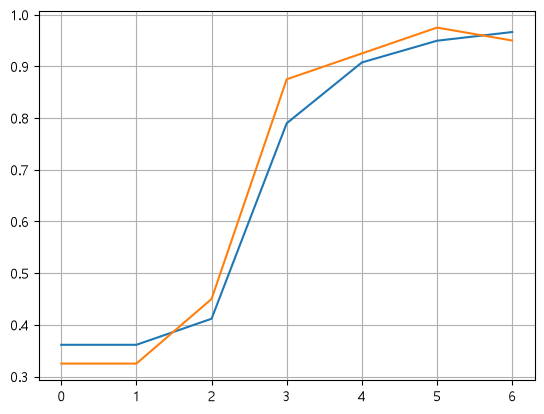

In [39]:
list1 = list(range(7))
plt.plot(list1, train_score)
plt.plot(list1, test_score)
plt.grid()
plt.show()

In [43]:
# 실제입력받아 예측하시오.
predict = lr.predict(test_scaled[:1])
print('분류생선 : ',predict)
proba = lr.predict_proba(test_scaled[:1])

# if문을 넣어서 확인
if predict[0] == 'Bream':
    result = proba[0][0]
elif predict[0] == 'Parkki':
    result = proba[0][1]    
elif predict[0] == 'Perch':
    result = proba[0][2]    
elif predict[0] == 'Pike':
    result = proba[0][3]    
elif predict[0] == 'Roach':
    result = proba[0][4]    
elif predict[0] == 'Smelt':
    result = proba[0][5]    
elif predict[0] == 'Whitefish':
    result = proba[0][6]    

print('확률 : ',result)

분류생선 :  ['Bream']
확률 :  0.9999346706682632


In [45]:
proba = lr.predict_proba(test_scaled[:1])
decisions = lr.decision_function(train_scaled[:1])
soft1 = softmax(decisions,axis=1) #axis=1은 행방향

print(lr.classes_)
np.round(soft1, decimals=3)

['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


array([[0.   , 0.003, 0.856, 0.001, 0.069, 0.064, 0.007]])